# Vanhamäki (2020) SECS Example

This notebook reproduces a compact spherical elementary current system (SECS) workflow using the example grid and magnetometer perturbations bundled with `SECSpy`. The goal is to infer a divergence-free equivalent ionospheric current sheet from ground magnetometer data, then visualise the measured perturbations, reconstructed magnetic field, fitted SECS amplitudes, and derived equivalent currents.

The steps follow the structure of the `SECSpy.SECS` module: define pole and evaluation grids, load magnetometer vectors, build the fitting matrix, solve for SECS amplitudes, evaluate magnetic fields and currents, and finally plot the results in a cubed-sphere projection.


## Imports

The notebook uses `SECSpy.Example` for the bundled Vanhamäki-style grid and magnetometer data, `SECSpy.SECS` for the inversion, and `secsy.cubedsphere` plus Matplotlib for plotting. Magnetic data are handled in SI units inside the model and converted to nT or A km$^{-1}$ only when visualised.


In [1]:
import matplotlib.pyplot as plt
from SECSpy import ExampleData, ExampleGrid
from SECSpy import SECS
from SECSpy.Plotting_Tools import add_image, add_land, add_ocean, add_natural_earth_feature, align_axis_below
import numpy as np
from secsy.cubedsphere import CSgrid, CSprojection
from apexpy import Apex
import datetime as dt

## Build the SECS Geometry

`ExampleGrid()` returns two longitude/latitude grids from the Vanhamäki (2020) example: SEC pole nodes and evaluation points. The pole nodes are where the elementary current systems are placed, while the evaluation grid is where we later reconstruct magnetic-field perturbations and horizontal currents.

`SECS(...)` stores this geometry and precomputes angular separations between each pole and each evaluation point. With the default settings the current sheet is placed at `RE + 110 km`, representing the ionospheric F-region current altitude.


In [2]:
node_lon, node_lat, eval_lon, eval_lat= ExampleGrid()
poles= SECS(node_lon, node_lat, eval_lon, eval_lat)

## Load the Example Magnetometer Data

`ExampleData()` returns the ground magnetic perturbation measurements and station locations used by this example. The field components are in Tesla: `South` is the theta/southward component, `East` is the phi/eastward component, and `Up` is the radial component. `MagLon` and `MagLat` give the station coordinates in degrees.

The SEC routines expect the measured vector as east, south, and up arguments, then internally assemble the inversion vector in south/east/up order to match the fitting matrix.


In [3]:
South, East, Up, MagLon, MagLat= ExampleData()

## Construct the Inversion Matrix

`Fitting_Matrix(MagLon, MagLat)` builds the magnetic-field response matrix for unit-amplitude SEC poles at the magnetometer locations. For the default `divergence-free` system, each column describes the south, east, and radial magnetic perturbation produced by one SEC pole.

The method then forms a Moore-Penrose pseudoinverse using singular value decomposition. Singular values smaller than `cond * max(singular values)` are discarded, so the stored `poles.fitting_matrix['divergence-free']` maps the measured magnetometer vector to the best-fitting SEC amplitudes.


In [4]:
poles.Fitting_Matrix(MagLon, MagLat)

(array([[-2.27150646e-15, -4.45871653e-15, -6.74105140e-15, ...,
         -4.23862146e-14, -4.15383213e-14, -4.07194702e-14],
        [ 9.03601931e-14,  8.60565908e-14,  7.80928360e-14, ...,
         -3.99420839e-14, -3.95367277e-14, -3.91145317e-14],
        [ 1.95813712e-14,  1.63381042e-14,  1.26804195e-14, ...,
         -4.35601011e-14, -4.28178058e-14, -4.20852464e-14],
        ...,
        [ 2.20458569e-14,  2.29876614e-14,  2.39788077e-14, ...,
          1.45917130e-13,  1.43777580e-13,  1.39987939e-13],
        [ 4.55455298e-14,  4.56969727e-14,  4.57484052e-14, ...,
          1.74638706e-14,  1.68271025e-14,  1.62132846e-14],
        [ 4.36400593e-14,  4.41528308e-14,  4.45839108e-14, ...,
          2.03588883e-14,  1.95940167e-14,  1.88597397e-14]],
       shape=(102, 1440)),
 array([[ 1.46781573e+21,  1.52544358e+21,  1.57383238e+21, ...,
         -1.90993431e+20, -1.83653776e+20, -1.78173597e+20],
        [ 1.52544358e+21,  1.59245671e+21,  1.65118044e+21, ...,
         -1.

## Reconstruct the Magnetic Field on the Evaluation Grid

`Magnetic_Field(East, South, Up)` first solves for the SECS pole amplitudes using the fitting matrix, then evaluates the magnetic perturbation from those poles at every evaluation-grid point. The returned tuple contains radial, eastward, and northward components in Tesla.

The multiplication by `1e9` converts the modelled perturbations to nanotesla for plotting beside the measured magnetometer vectors.


In [5]:
Mag= [mag*1e9 for mag in poles.Magnetic_Field(East, South, Up)]

## Evaluate the Equivalent Currents

`Currents(East, South, Up)` uses the same fitted SECS amplitudes, but evaluates the horizontal divergence-free current field rather than the magnetic field. By default it evaluates at the ionospheric current radius stored in the model, so the result represents the equivalent ionospheric current sheet.

The returned arrays are eastward and northward current components in amps.


In [6]:
Cur= poles.Currents(East, South, Up)

## Prepare the Map Projection

The model geometry is geographic, but the figure is drawn in a cubed-sphere projection centred near northern Fennoscandia. `CSgrid` defines the plotting plane and `geo2cube` converts both SEC pole locations and evaluation points into projected `xi`/`eta` coordinates.


In [7]:
lon_centre= 20
lat_centre= 68.1
Gridproj= CSprojection((lon_centre, lat_centre), 0)
plot_grid=CSgrid(Gridproj, 2500, 3000, 50., 50.)
node_xi, node_eta= plot_grid.projection.geo2cube(node_lon, node_lat)
eval_xi, eval_eta= plot_grid.projection.geo2cube(eval_lon, eval_lat)

## Set Up the Three-Panel Figure

The figure is arranged as three map panels with matching horizontal colour bars: measured and modelled magnetic perturbations, SEC amplitudes, and divergence-free currents. Bundled Natural Earth ocean, land, lake, and coastline features are projected through the cubed-sphere grid so the geographic context matches the plotted vectors and grid points.


ZeroDivisionError: division by zero

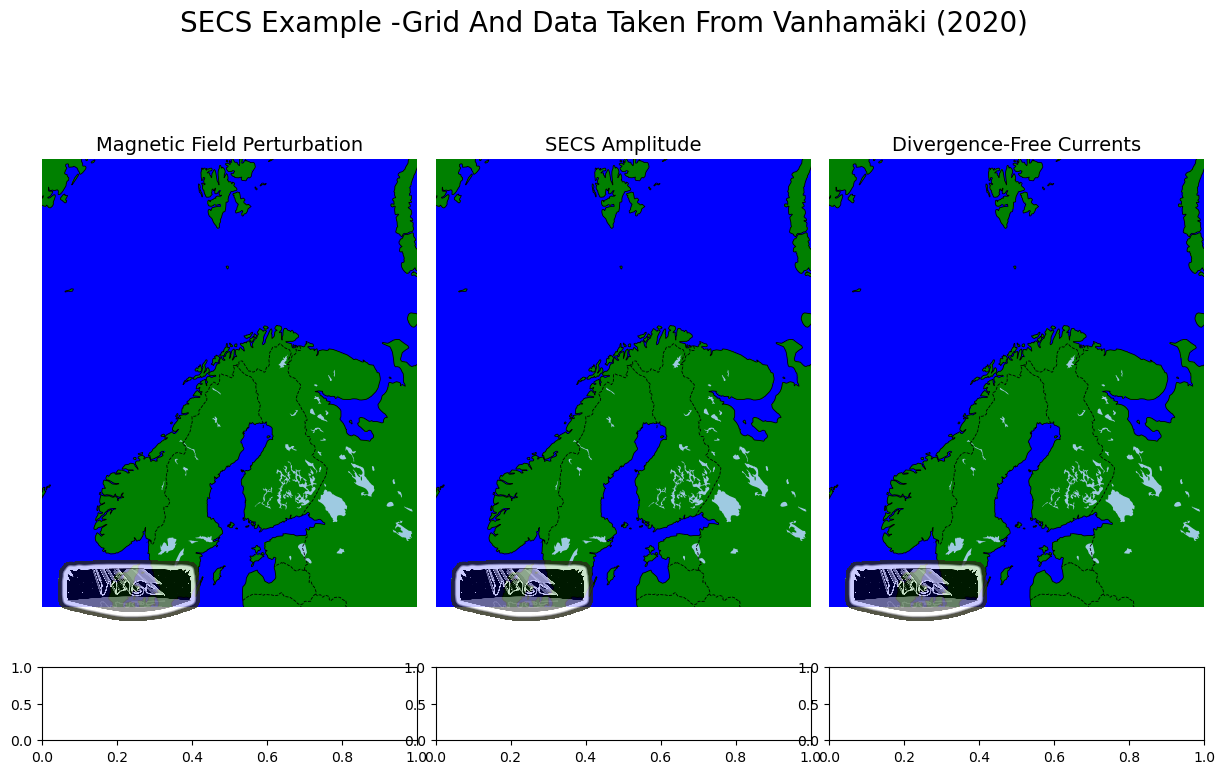

In [ ]:
fig=plt.figure(figsize=(15, 20))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 1], height_ratios=[1, .05], hspace=0, wspace=0.05)
mag_ax = fig.add_subplot(gs[0, 0])
mag_ax.set_title('Magnetic Field Perturbation', fontsize=14)
mag_cax = fig.add_subplot(gs[1, 0])
amps_ax = fig.add_subplot(gs[0, 1])
amps_ax.set_title('SECS Amplitude', fontsize=14)
amps_cax = fig.add_subplot(gs[1, 1])
cur_ax = fig.add_subplot(gs[0, 2])
cur_ax.set_title('Divergence-Free Currents', fontsize=14)
cur_cax = fig.add_subplot(gs[1, 2])
fig.suptitle('SECS Example -Grid And Data Taken From Vanhamäki (2020)', y=.7, size=20)

for ax, cax in zip([mag_ax, amps_ax, cur_ax], [mag_cax, amps_cax, cur_cax]):
    add_ocean(ax, plot_grid, resolution='50m', facecolor='blue', zorder=-4)
    add_land(ax, plot_grid, resolution='50m', facecolor='green', zorder=-3)
    add_natural_earth_feature(
        ax, plot_grid, 'lakes', resolution='50m',
        facecolor='#9ecae1', edgecolor='none', linewidth=0, zorder=-2,
    )
    add_natural_earth_feature(
        ax, plot_grid, 'coastline', resolution='50m',
        edgecolor='black', linewidth=0.6, zorder=-1,
    )
    add_natural_earth_feature(
        ax, plot_grid, 'borders', resolution='50m',
        edgecolor='black', linewidth=0.6, zorder=-1, linestyle='--'
    )
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_xlim(plot_grid.xi.min(), plot_grid.xi.max())
    ax.set_ylim(plot_grid.eta.min(), plot_grid.eta.max())
    align_axis_below(ax, cax, pad=0.03)
    add_image(ax, 'https://space.fmi.fi/image/www/images/IMAGE_logo_2.png',
                location=(-0.1, -0.2), zoom=0.11, alpha=0.8)

## Overlay the Measured Magnetic Field

The station measurements are projected into the cubed-sphere plotting coordinates. The horizontal arrows use eastward and northward components, so the southward component is negated with `-South`. The station markers are coloured by the radial perturbation `Up`, all converted from Tesla to nanotesla.


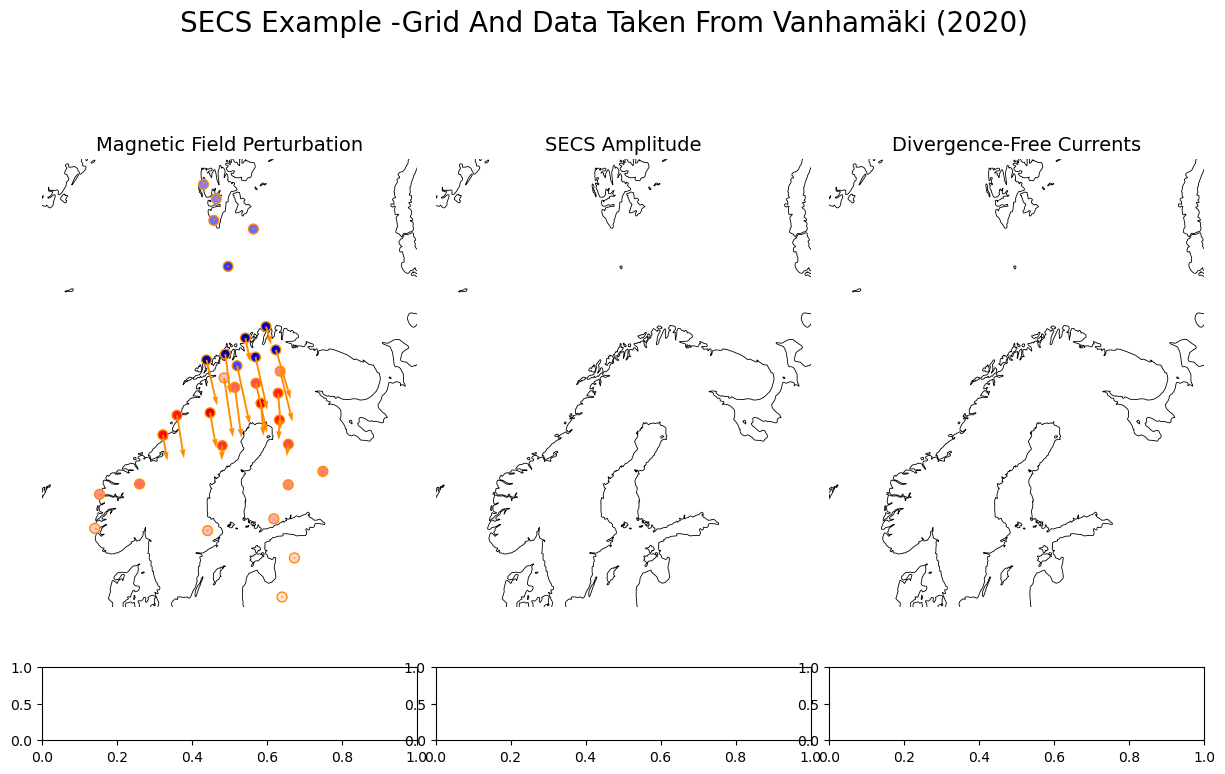

In [ ]:


xi, eta, Axi, Aeta = plot_grid.projection.vector_cube_projection(East*1e9, -South*1e9, MagLon, MagLat)
mag_ax.quiver(xi, eta, Axi, Aeta, zorder=120, color='darkorange', scale=(5e3), width=0.005)
mag_ax.scatter(xi, eta, marker= 'o', c= Up*1e9, label= 'Magnetometer \n Station',
                    cmap= 'seismic', vmin= -np.max(np.abs(Mag[0])), vmax= np.max(np.abs(Mag[0])), zorder=110, s=50,
                    edgecolor='darkorange')
fig

## Plot the Modelled Magnetic Field

The reconstructed field is evaluated on the regular evaluation grid. The scatter plot shows radial perturbation and the arrows show the modelled horizontal perturbation. Using the same colour limits as the measured stations makes the observed and reconstructed radial fields directly comparable.


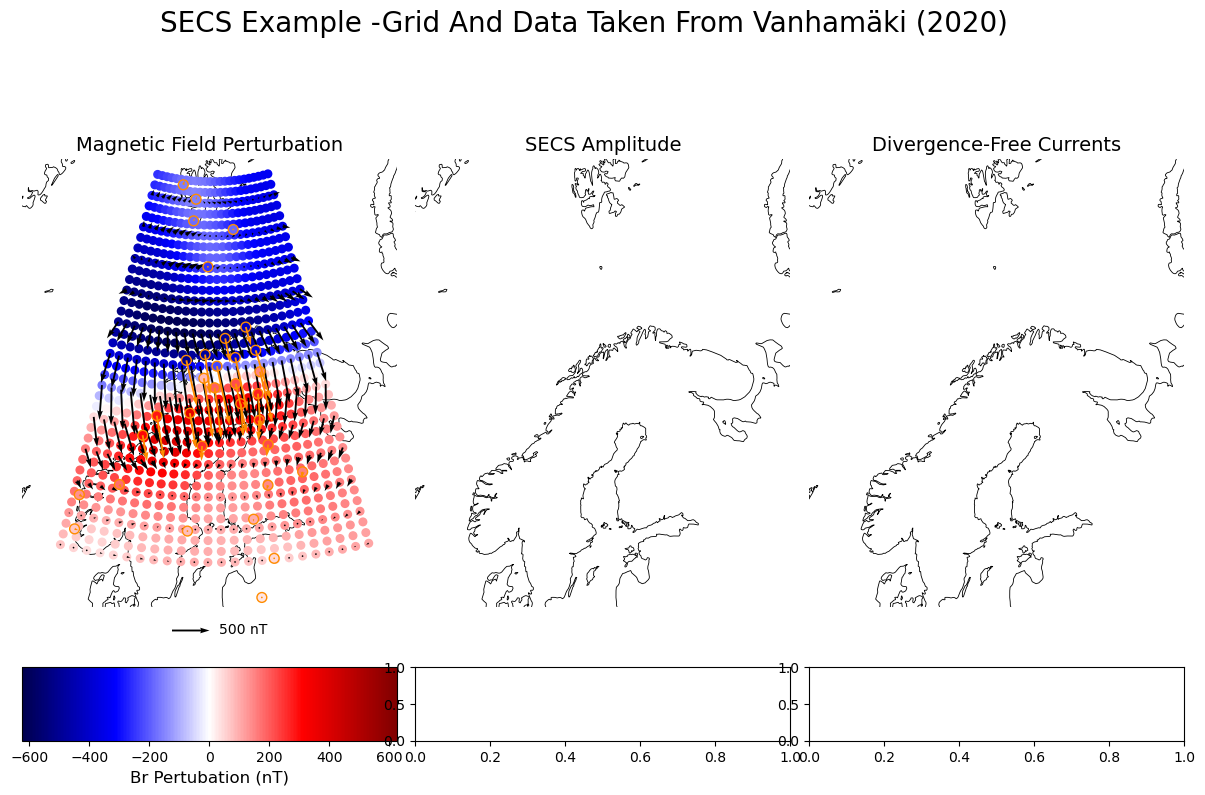

In [ ]:
Axi, Aeta = plot_grid.projection.vector_cube_projection(*Mag[1:], eval_lon, eval_lat, return_xi_eta=False)

mags_s= mag_ax.scatter(eval_xi, eval_eta, marker= 'o', c= Mag[0], label= 'Magnetometer \n Station',
                    cmap= 'seismic', vmin= -np.max(np.abs(Mag[0])), vmax= np.max(np.abs(Mag[0])), zorder=1, s=30)
mag_cbar= fig.colorbar(mags_s, cax=mag_cax, orientation='horizontal')
mag_cbar.set_label('Br Pertubation (nT)', fontsize=12)
mag_quiver= mag_ax.quiver(eval_xi[::3], eval_eta[::3], Axi[::3], Aeta[::3], zorder=100, color='k', scale=(5e3), width=0.005)
mag_ax.quiverkey(mag_quiver, 0.5, -0.05, 500, '500 nT', labelpos='E', coordinates='axes', color='k')
fig

## Plot the SEC Pole Amplitudes

`Amplitude(East, South, Up)` returns the fitted amplitude of each elementary current pole. The plot places those amplitudes at the SECS pole-node coordinates. Values are multiplied by `1e-3` so the colour bar is labelled in kA.


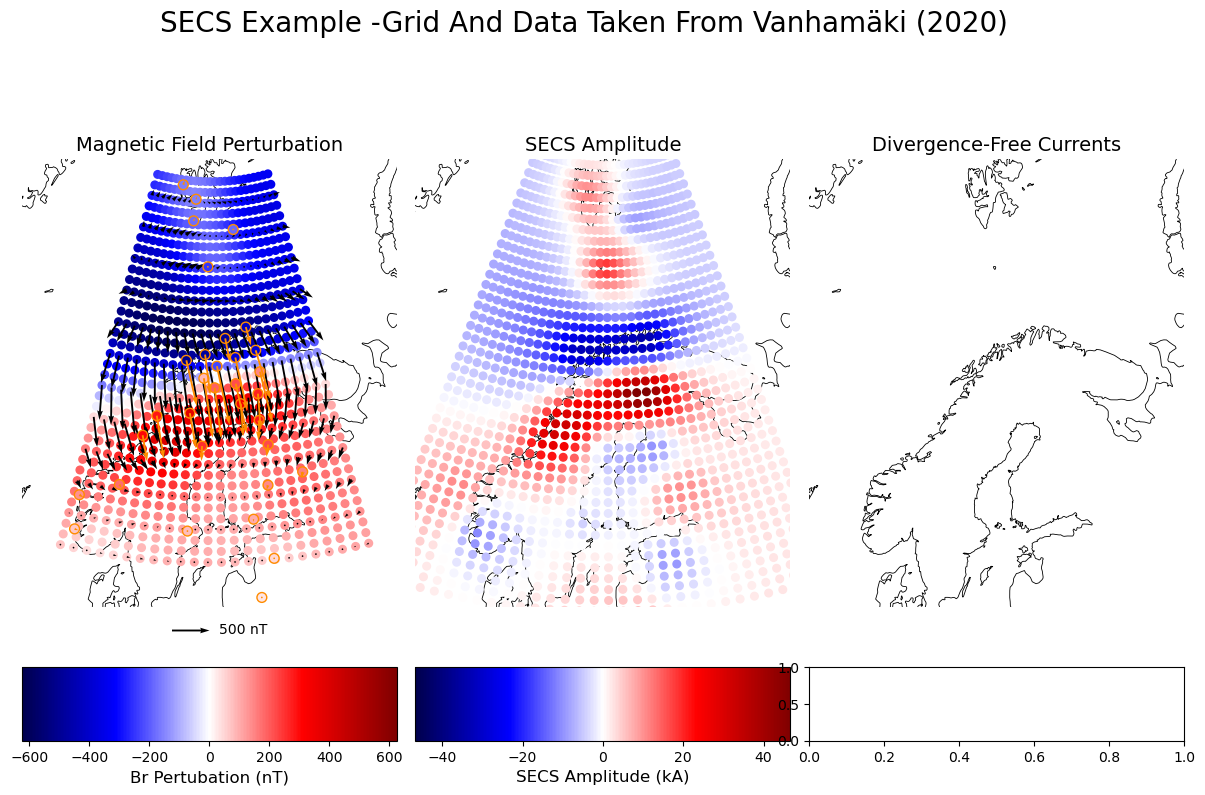

In [ ]:
amps= poles.Amplitude(East, South, Up)*1e-3
amps_s= amps_ax.scatter(node_xi, node_eta, marker= 'o',
                        c= amps, cmap= 'seismic', zorder=1, s=30,
                        vmin= -np.max(np.abs(amps)), vmax= np.max(np.abs(amps)))
amps_cbar= fig.colorbar(amps_s, cax=amps_cax, orientation='horizontal')
amps_cbar.set_label('SECS Amplitude (kA)', fontsize=12)
fig

## Plot the Divergence-Free Current Field

The current vectors returned by `Currents` are converted to mA m$^{-1}$, equivalently A km$^{-1}$, for display. Arrows show direction and the background colour shows horizontal current magnitude. This final panel is the equivalent current pattern implied by the fitted divergence-free SECS system.


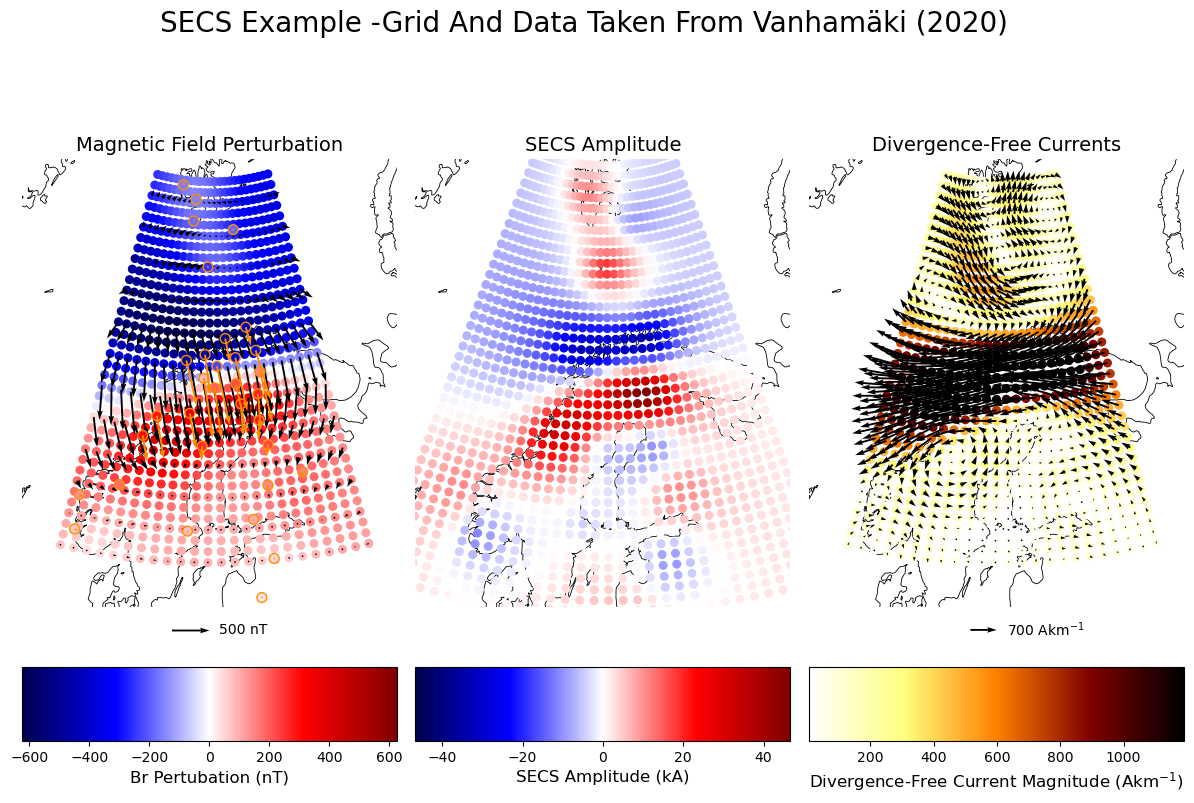

In [ ]:
cur_mag= ((Cur[0]**2 + Cur[1]**2)**.5)*1e3
cur_quiver= cur_ax.quiver(eval_xi, eval_eta,
                *plot_grid.projection.vector_cube_projection(Cur[0]*1e3, Cur[1]*1e3,
                                                                eval_lon, eval_lat,
                                                                return_xi_eta=False),
                zorder=100, color='k', scale=1e4, width=0.005)
cur_ax.quiverkey(cur_quiver, 0.5, -0.05, 700, label='700 Akm$^{-1}$', labelpos='E', coordinates='axes')
cur_s= cur_ax.scatter(eval_xi, eval_eta, marker= 'o',
                        c= cur_mag, cmap= 'afmhot_r', zorder=1, s=30,
                        vmin= np.min(cur_mag), vmax= .6*np.max(cur_mag))
cur_cbar= fig.colorbar(cur_s, cax=cur_cax, orientation='horizontal')
cur_cbar.set_label('Divergence-Free Current Magnitude (Akm$^{-1}$)', fontsize=12)
fig